# 1. Test signal and EMD

One noisy ECG built as in Sec. IV of the paper, its EMD, and where each noise ends up in the IMFs.
The paper filters PLI on IMF1, BW on IMF5-8, EM on IMF3-8 and MA on the whole signal.
This notebook computes everything live (EMD takes under a second).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # project root, so `src` can be imported

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import FIGURES_DIR, RESULTS_DIR

pd.set_option("display.precision", 2)

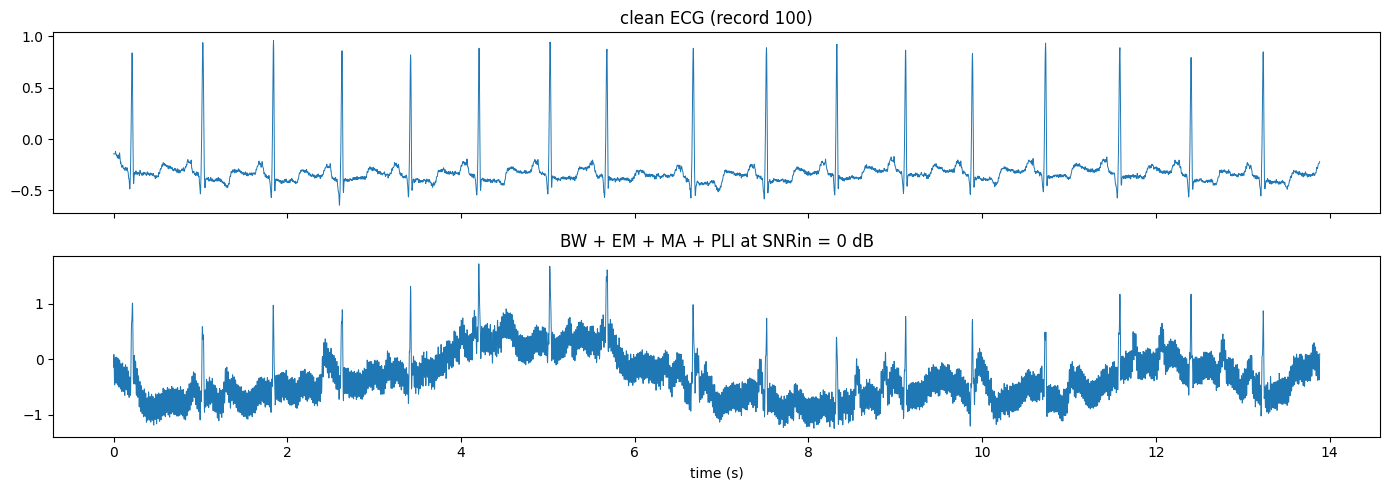

In [2]:
from src.config import FS, NOISE_PATHS
from src.data import make_case, shift_and_filter
from src.emd import decompose

c = make_case(100, ("bw", "em", "ma", "pli"), 0, "raw")  # record 100, all four noises, SNRin 0 dB
imfs, r = decompose(c["noisy"])

t = np.arange(5000) / FS
fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
ax[0].plot(t, c["clean"][:5000], lw=0.7); ax[0].set_title("clean ECG (record 100)")
ax[1].plot(t, c["noisy"][:5000], lw=0.7); ax[1].set_title("BW + EM + MA + PLI at SNRin = 0 dB")
ax[1].set_xlabel("time (s)")
plt.tight_layout()

## IMFs (PyEMD, 10 sifting iterations per IMF)

Each IMF is roughly an octave lower than the one before. IMF1 holds the 60 Hz PLI.

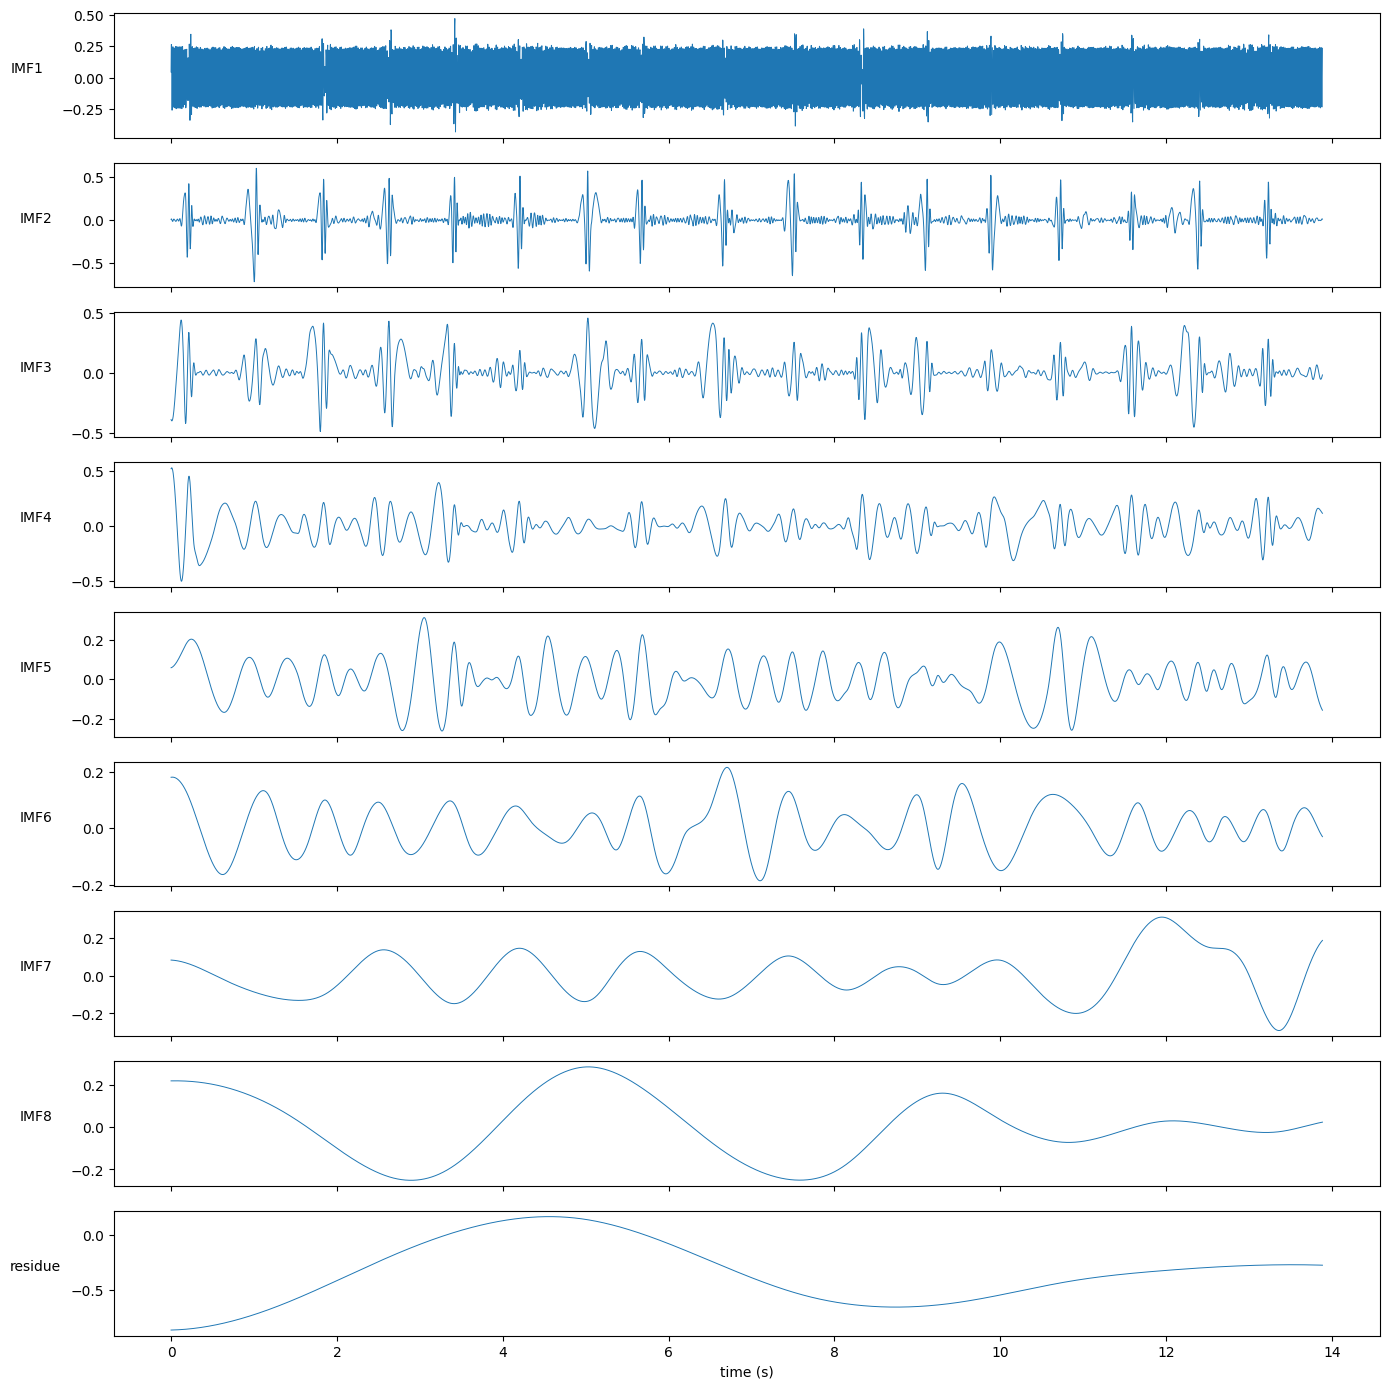

In [3]:
fig, axes = plt.subplots(9, 1, figsize=(14, 14), sharex=True)
for k in range(8):
    axes[k].plot(t, imfs[k][:5000], lw=0.7)
    axes[k].set_ylabel(f"IMF{k + 1}", rotation=0, labelpad=25)
axes[8].plot(t, r[:5000], lw=0.7)
axes[8].set_ylabel("residue", rotation=0, labelpad=25)
axes[8].set_xlabel("time (s)")
plt.tight_layout()

In [4]:
def zero_cross_freq(x):
    return np.sum(np.diff(np.sign(x - x.mean())) != 0) / 2 / (len(x) / FS)

pd.DataFrame({"zero-crossing frequency (Hz)": [zero_cross_freq(x) for x in list(imfs) + [r]]},
             index=[f"IMF{k + 1}" for k in range(8)] + ["residue"]).T

,IMF1,IMF2,IMF3,IMF4,IMF5,IMF6,IMF7,IMF8,residue
zero-crossing frequency (Hz),59.98,22.78,10.36,5.46,2.72,1.34,0.6,0.24,0.1


## Where does each noise go?

Correlation of each noise (as added to the ECG) with each IMF and the residue.
BW and EM are slow: part of them is in the **residue**, which the paper adds back unfiltered.
That is why the code also filters the residue in the BW and EM branches (`FILTER_RESIDUE` in `src/config.py`).

In [5]:
added = {"pli": c["refs"]["pli"]}
added.update({n: shift_and_filter(c["refs"][n], *NOISE_PATHS[n]) for n in ("bw", "em", "ma")})
parts = {f"IMF{k + 1}": imfs[k] for k in range(8)} | {"residue": r - r.mean()}
pd.DataFrame({n: {p: abs(np.corrcoef(x, v)[0, 1]) for p, x in parts.items()} for n, v in added.items()}).T

,IMF1,IMF2,IMF3,IMF4,IMF5,IMF6,IMF7,IMF8,residue
pli,9.91e-01,2.66e-04,1.07e-04,9.11e-05,1.18e-05,4.10e-05,1.33e-05,1.84e-05,5.87e-05
bw,1.17e-03,7.08e-03,8.10e-03,6.06e-03,5.08e-03,4.81e-02,5.19e-02,4.52e-01,3.63e-01
em,9.49e-04,3.41e-02,4.88e-02,9.46e-02,2.05e-01,2.05e-01,3.08e-01,5.25e-01,2.05e-01
ma,8.73e-03,4.88e-02,1.36e-03,3.19e-03,1.08e-03,3.23e-02,1.88e-01,1.71e-01,2.64e-01
